In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from src.preprocessing import (
    montar_dataframe_bruto, segmentar_sinal, montar_dataframe_janelas, carregar_rpm
)
from src.features import montar_dataframe_features, calcular_frequencias_falha

In [2]:
import sys
sys.path.append("..")

from src.preprocessing import montar_dataframe_bruto, segmentar_sinal, montar_dataframe_janelas
from src.features import montar_dataframe_features

In [3]:
from scipy.io import loadmat

dados = loadmat("../data/raw/Normal_0.mat")
print(dados.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])


In [4]:
sinal = dados['X097_DE_time']
print("Formato (shape):", sinal.shape)
print("Primeiros 10 valores:", sinal[:10])

Formato (shape): (243938, 1)
Primeiros 10 valores: [[ 0.05319692]
 [ 0.08866154]
 [ 0.09971815]
 [ 0.05862092]
 [-0.00458954]
 [-0.056952  ]
 [-0.07176369]
 [-0.05862092]
 [-0.04652123]
 [-0.04985908]]


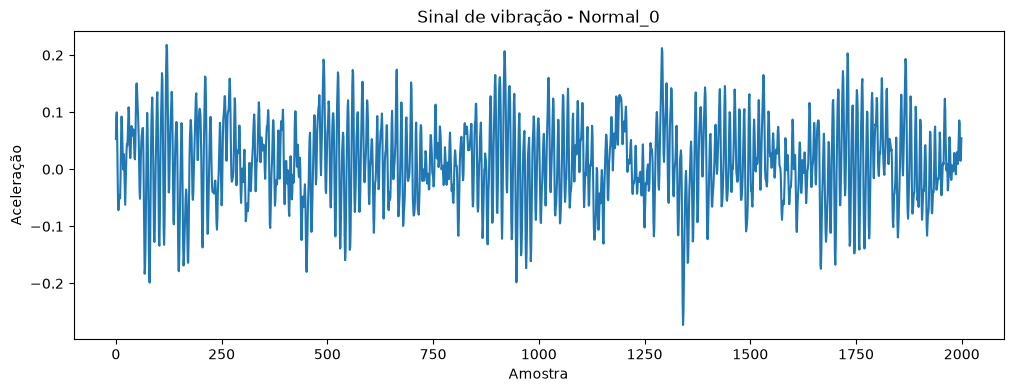

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(sinal[:2000])  # primeiros 2000 pontos
plt.title("Sinal de vibração - Normal_0")
plt.xlabel("Amostra")
plt.ylabel("Aceleração")
plt.show()

In [6]:
dados_falha = loadmat("../data/raw/IR021_0.mat")
print(dados_falha.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X209_DE_time', 'X209_FE_time', 'X209_BA_time', 'X209RPM'])


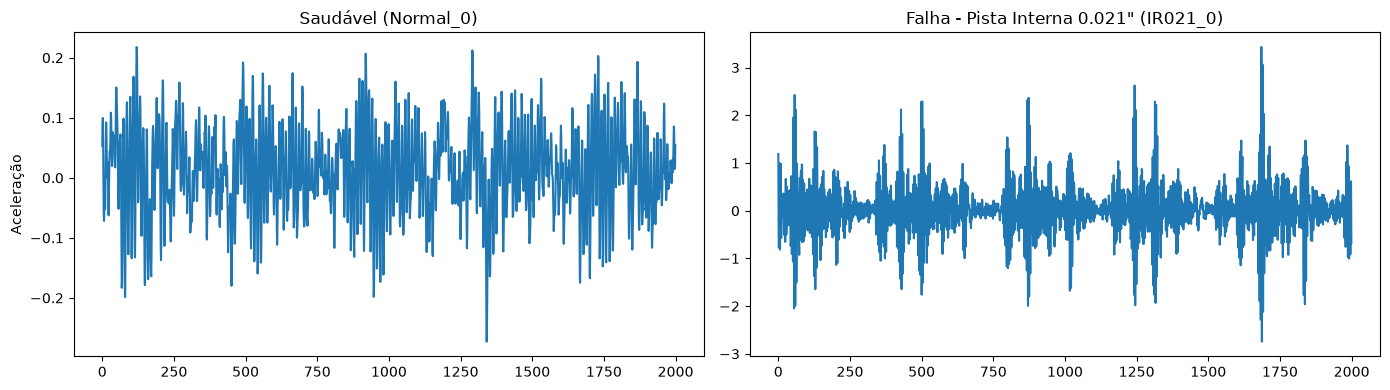

In [7]:
sinal_falha = dados_falha['X209_DE_time']

fig, axs = plt.subplots(1, 2, figsize=(14, 4))

axs[0].plot(sinal[:2000])
axs[0].set_title("Saudável (Normal_0)")
axs[0].set_ylabel("Aceleração")

axs[1].plot(sinal_falha[:2000])
axs[1].set_title("Falha - Pista Interna 0.021\" (IR021_0)")

plt.tight_layout()
plt.show()

In [8]:
def encontrar_chave_de_time(dados: dict) -> str:
    for chave in dados.keys():
        if "DE_time" in chave:
            return chave
    raise ValueError("Nenhuma chave DE_time encontrada no arquivo.")

# Testando:
chave = encontrar_chave_de_time(dados_falha)
print("Chave encontrada:", chave)

Chave encontrada: X209_DE_time


In [9]:
from scipy.io import loadmat
import numpy as np

def carregar_sinal(caminho_arquivo: str) -> np.ndarray:
    """
    Lê um arquivo .mat do CWRU e retorna o sinal de vibração do Drive End (DE)
    como um vetor 1D (achatado).
    """
    dados = loadmat(caminho_arquivo)

    # Reaproveitando a lógica que você validou na etapa anterior
    chave_de = None
    for chave in dados.keys():
        if "DE_time" in chave:
            chave_de = chave
            break

    if chave_de is None:
        raise ValueError(f"Nenhuma coluna DE_time encontrada em {caminho_arquivo}")

    sinal = dados[chave_de]
    return sinal.flatten() 

In [10]:
import sys
sys.path.append("..")

from src.preprocessing import montar_dataframe_bruto

In [11]:
import os
from scipy.io import loadmat

pasta = "../data/raw"
arquivos_com_erro = []

for nome_arquivo in sorted(os.listdir(pasta)):
    if not nome_arquivo.endswith(".mat"):
        continue
    caminho = os.path.join(pasta, nome_arquivo)
    try:
        loadmat(caminho)
    except Exception as e:
        print(f"[CORROMPIDO] {nome_arquivo}: {e}")
        arquivos_com_erro.append(nome_arquivo)

print("\nTotal de arquivos com problema:", len(arquivos_com_erro))
print(arquivos_com_erro)


Total de arquivos com problema: 0
[]


In [12]:
df = montar_dataframe_bruto("../data/raw")
print(df.shape)
df.head()

(40, 7)


,arquivo,classe,severidade,posicao,carga,sinal,n_amostras
0,B007_0.mat,B,007,NaN,0,"[-0.0027613972055888225, -0.09632403193612774,...",122571
1,B007_1.mat,B,007,NaN,1,"[-0.07212119760479042, 0.30310395209580837, 0....",121410
2,B007_2.mat,B,007,NaN,2,"[-0.3144744111776447, 0.12198878243512974, 0.3...",121556
3,B007_3.mat,B,007,NaN,3,"[0.09031393213572854, 0.22497265469061875, -0....",121556
4,B014_0.mat,B,014,NaN,0,"[-0.46781317365269465, 0.1790035129740519, 0.4...",121846


In [13]:
print(df["classe"].value_counts())
print("\nn_amostras - mínimo, máximo, média:")
print(df["n_amostras"].min(), df["n_amostras"].max(), df["n_amostras"].mean())

classe
B         12
IR        12
OR        12
Normal     4
Name: count, dtype: int64

n_amostras - mínimo, máximo, média:
121265 485643 152213.4


In [14]:
df_janelas = montar_dataframe_janelas(df, tamanho_janela=2048)
print(df_janelas.shape)
df_janelas["classe"].value_counts()

(2953, 6)


classe
Normal    828
IR        709
B         708
OR        708
Name: count, dtype: int64

In [15]:
df.groupby("classe")["n_amostras"].agg(["mean", "min", "max", "sum"])

,mean,min,max,sum
classe,,,,
B,121930.500000,121410,122571,1463166
IR,121923.083333,121265,122917,1463077
Normal,424346.750000,243938,485643,1697387
OR,122075.500000,121410,122571,1464906


In [16]:
import numpy as np
from scipy.stats import kurtosis

def calcular_rms(janela: np.ndarray) -> float:
    return np.sqrt(np.mean(janela ** 2))

def calcular_curtose(janela: np.ndarray) -> float:
    return kurtosis(janela, fisher=False)  # fisher=False mantém a referência em 3.0

def calcular_fator_crista(janela: np.ndarray) -> float:
    pico = np.max(np.abs(janela))
    rms = calcular_rms(janela)
    return pico / rms

In [17]:
sinal_uniforme = np.random.normal(0, 0.1, 2048)  # ruído normal
sinal_com_pico = sinal_uniforme.copy()
sinal_com_pico[100] = 5.0  # insere um pico artificial isolado

print("Uniforme -> RMS:", calcular_rms(sinal_uniforme), "| Curtose:", calcular_curtose(sinal_uniforme), "| Crista:", calcular_fator_crista(sinal_uniforme))
print("Com pico -> RMS:", calcular_rms(sinal_com_pico), "| Curtose:", calcular_curtose(sinal_com_pico), "| Crista:", calcular_fator_crista(sinal_com_pico))

Uniforme -> RMS: 0.10025047565149063 | Curtose: 2.94139049827366 | Crista: 3.4050491590430187
Com pico -> RMS: 0.14918607534619902 | Curtose: 615.9986451213614 | Crista: 33.51519227513073


In [18]:
from src.features import montar_dataframe_features

df_features = montar_dataframe_features(df_janelas)
print(df_features.shape)
df_features.head()

(2953, 8)


,arquivo,classe,severidade,posicao,carga,rms,curtose,fator_crista
0,B007_0.mat,B,007,NaN,0,0.134602,2.899283,3.579324
1,B007_0.mat,B,007,NaN,0,0.139796,3.075603,3.641542
2,B007_0.mat,B,007,NaN,0,0.133587,2.600836,3.235633
3,B007_0.mat,B,007,NaN,0,0.140045,3.094300,3.716252
4,B007_0.mat,B,007,NaN,0,0.141407,2.862215,3.448413


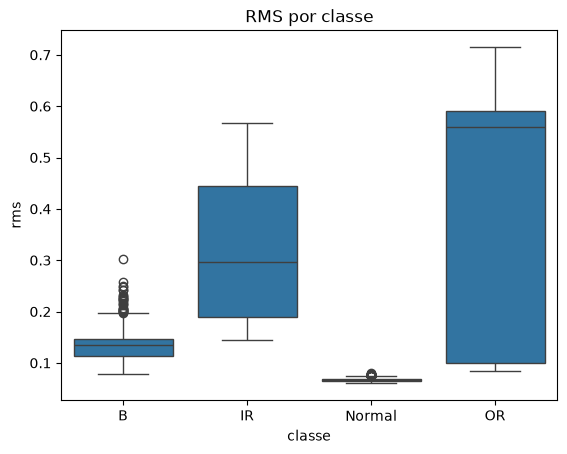

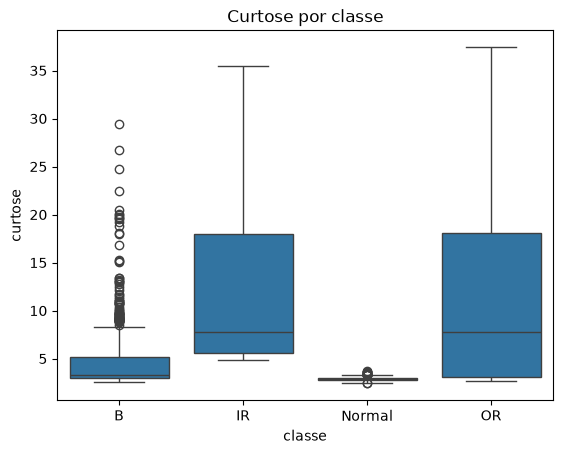

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df_features, x="classe", y="rms")
plt.title("RMS por classe")
plt.show()

sns.boxplot(data=df_features, x="classe", y="curtose")
plt.title("Curtose por classe")
plt.show()

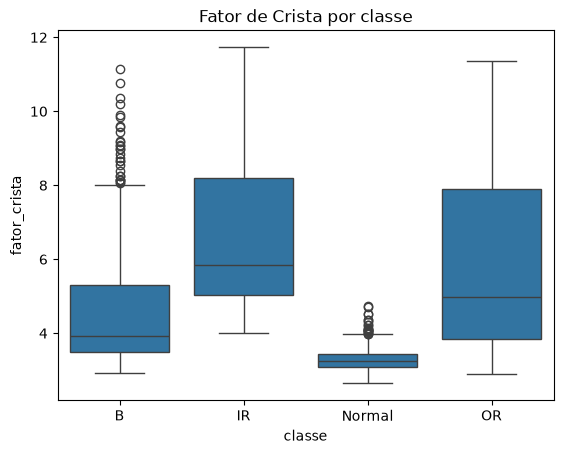

In [20]:
sns.boxplot(data=df_features, x="classe", y="fator_crista")
plt.title("Fator de Crista por classe")
plt.show()

In [21]:
from sklearn.model_selection import train_test_split

arquivos_unicos = df_features[["arquivo", "classe"]].drop_duplicates()
print(arquivos_unicos.shape)

(40, 2)


In [22]:
# Passo 2: divide os NOMES DOS ARQUIVOS em treino/teste, de forma estratificada pela classe
arquivos_treino, arquivos_teste = train_test_split(
    arquivos_unicos["arquivo"],
    test_size=0.3,
    stratify=arquivos_unicos["classe"],
    random_state=42,
)

print("Arquivos treino:", len(arquivos_treino))
print("Arquivos teste:", len(arquivos_teste))

Arquivos treino: 28
Arquivos teste: 12


In [23]:
df_treino = df_features[df_features["arquivo"].isin(arquivos_treino)]
df_teste = df_features[df_features["arquivo"].isin(arquivos_teste)]

print("Janelas treino:", df_treino.shape[0])
print("Janelas teste:", df_teste.shape[0])

Janelas treino: 2067
Janelas teste: 886


In [24]:
print(df_treino["classe"].value_counts(normalize=True))
print(df_teste["classe"].value_counts(normalize=True))

classe
Normal    0.285922
B         0.256894
IR        0.228834
OR        0.228350
Name: proportion, dtype: float64
classe
Normal    0.267494
IR        0.266366
OR        0.266366
B         0.199774
Name: proportion, dtype: float64


In [25]:
colunas_features = ["rms", "curtose", "fator_crista"]

X_treino = df_treino[colunas_features]
y_treino = df_treino["classe"]

X_teste = df_teste[colunas_features]
y_teste = df_teste["classe"]

print(X_treino.shape, y_treino.shape)
print(X_teste.shape, y_teste.shape)

(2067, 3) (2067,)
(886, 3) (886,)


In [26]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(random_state=42)
modelo_rf.fit(X_treino, y_treino)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [27]:
y_previsto = modelo_rf.predict(X_teste)

# Primeiras 10 previsões
comparacao = pd.DataFrame({
    "real": y_teste.values[:10],
    "previsto": y_previsto[:10]
})
print(comparacao)

  real previsto
0    B        B
1    B        B
2    B        B
3    B        B
4    B        B
5    B        B
6    B        B
7    B        B
8    B        B
9    B        B


In [28]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

acuracia = accuracy_score(y_teste, y_previsto)
print(f"Acurácia: {acuracia:.2%}")

print("\nRelatório de classificação:")
print(classification_report(y_teste, y_previsto))

Acurácia: 95.49%

Relatório de classificação:
              precision    recall  f1-score   support

           B       0.97      0.81      0.89       177
          IR       0.92      0.98      0.95       236
      Normal       0.98      1.00      0.99       237
          OR       0.95      0.99      0.97       236

    accuracy                           0.95       886
   macro avg       0.96      0.95      0.95       886
weighted avg       0.96      0.95      0.95       886



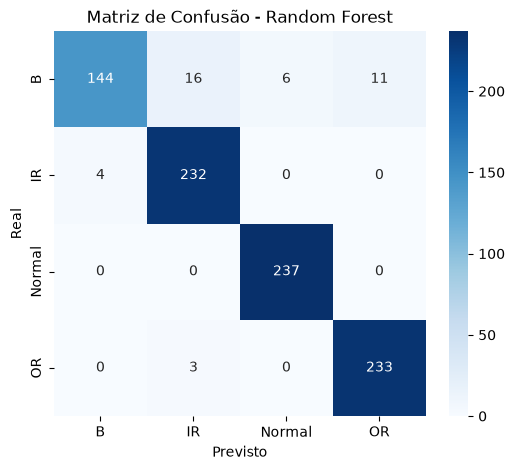

In [29]:
matriz = confusion_matrix(y_teste, y_previsto, labels=modelo_rf.classes_)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
            xticklabels=modelo_rf.classes_, yticklabels=modelo_rf.classes_)
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de Confusão - Random Forest")
plt.show()

In [30]:
rpm_teste = carregar_rpm("../data/raw/Normal_0.mat")
print("RPM:", rpm_teste)

frequencias = calcular_frequencias_falha(rpm_teste)
print(frequencias)

RPM: 1796.0
{'bpfo': 107.30428106701365, 'bpfi': 162.09571893298633, 'bsf': 70.54453624139776}


In [31]:
import numpy as np

def calcular_fft(janela: np.ndarray, taxa_amostragem: int = 12000) -> tuple:
    """
    Calcula o espectro de frequência (FFT) de uma janela de sinal.

    Retorna:
    - frequencias: os valores de frequência (eixo X do espectro), em Hz
    - magnitudes: a intensidade de cada frequência (eixo Y do espectro)
    """
    n = len(janela)

    fft_bruta = np.fft.fft(janela)
    magnitudes = np.abs(fft_bruta)

    frequencias = np.fft.fftfreq(n, d=1/taxa_amostragem)

    metade = n // 2
    return frequencias[:metade], magnitudes[:metade]

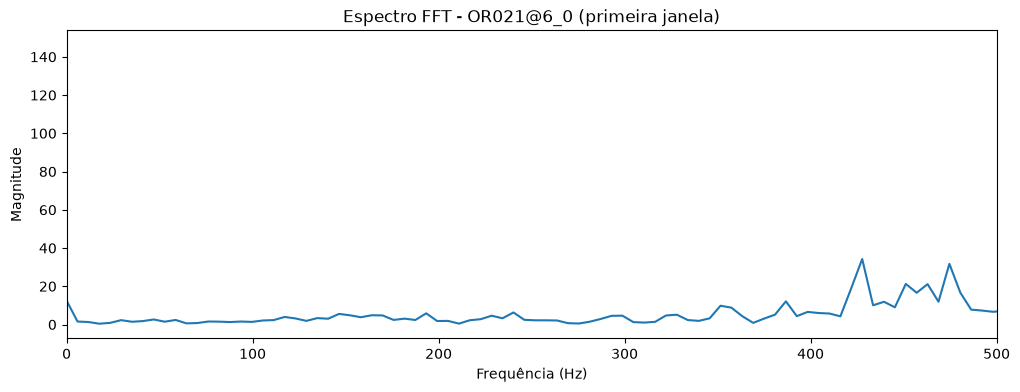

BPFO esperado: 107.30428106701365


In [32]:
import matplotlib.pyplot as plt

sinal_or = carregar_sinal("../data/raw/OR021@6_0.mat")
janela_or = segmentar_sinal(sinal_or, 2048)[0]

freqs, mags = calcular_fft(janela_or)

plt.figure(figsize=(12, 4))
plt.plot(freqs, mags)
plt.xlabel("Frequência (Hz)")
plt.ylabel("Magnitude")
plt.title("Espectro FFT - OR021@6_0 (primeira janela)")
plt.xlim(0, 500)
plt.show()

print("BPFO esperado:", calcular_frequencias_falha(carregar_rpm("../data/raw/OR021@6_0.mat"))["bpfo"])

In [33]:
from scipy.signal import hilbert

def calcular_envelope(janela: np.ndarray) -> np.ndarray:
    """
    Calcula o envelope de amplitude de um sinal usando a Transformada de
    Hilbert. O envelope revela a modulação de baixa frequência (causada
    pelo impacto periódico do defeito) que fica "escondida" sob a
    ressonância estrutural de alta frequência excitada pelo impacto.
    """
    sinal_analitico = hilbert(janela)
    envelope = np.abs(sinal_analitico)
    return envelope

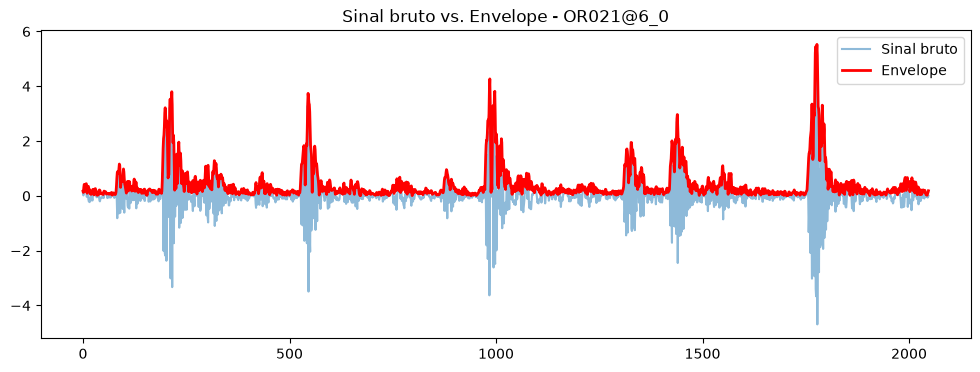

In [34]:
sinal_or = carregar_sinal("../data/raw/OR021@6_0.mat")
janela_or = segmentar_sinal(sinal_or, 2048)[0]

envelope = calcular_envelope(janela_or)

plt.figure(figsize=(12, 4))
plt.plot(janela_or, label="Sinal bruto", alpha=0.5)
plt.plot(envelope, label="Envelope", linewidth=2, color="red")
plt.legend()
plt.title("Sinal bruto vs. Envelope - OR021@6_0")
plt.show()

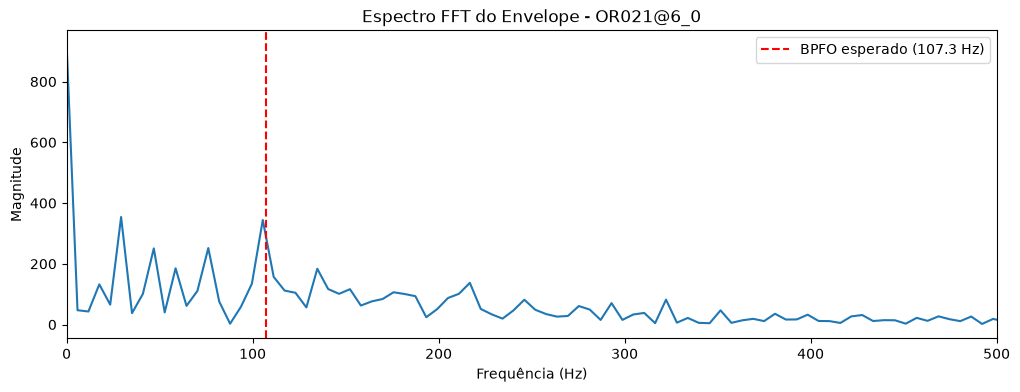

In [35]:
freqs_env, mags_env = calcular_fft(envelope)

bpfo_esperado = calcular_frequencias_falha(carregar_rpm("../data/raw/OR021@6_0.mat"))["bpfo"]

plt.figure(figsize=(12, 4))
plt.plot(freqs_env, mags_env)
plt.axvline(x=bpfo_esperado, color="red", linestyle="--", linewidth=1.5,
            label=f"BPFO esperado ({bpfo_esperado:.1f} Hz)")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Magnitude")
plt.title("Espectro FFT do Envelope - OR021@6_0")
plt.xlim(0, 500)
plt.legend()
plt.show()

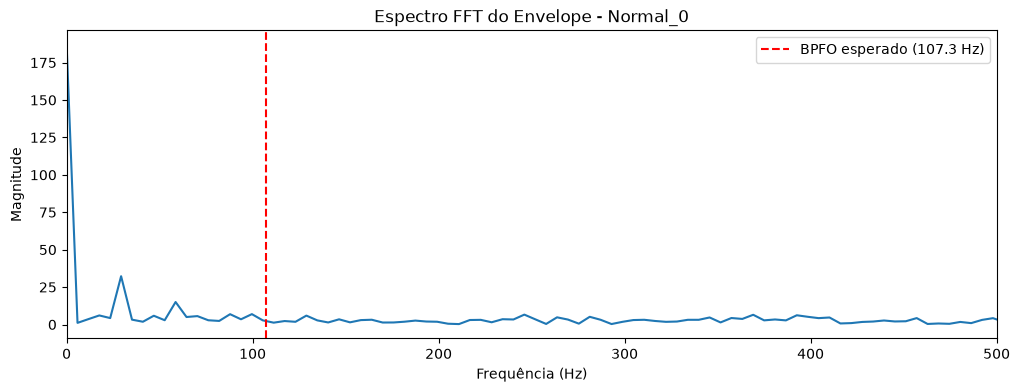

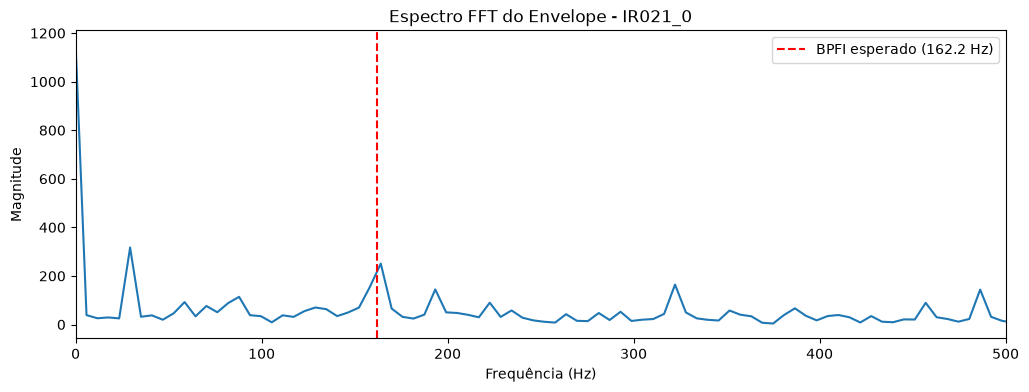

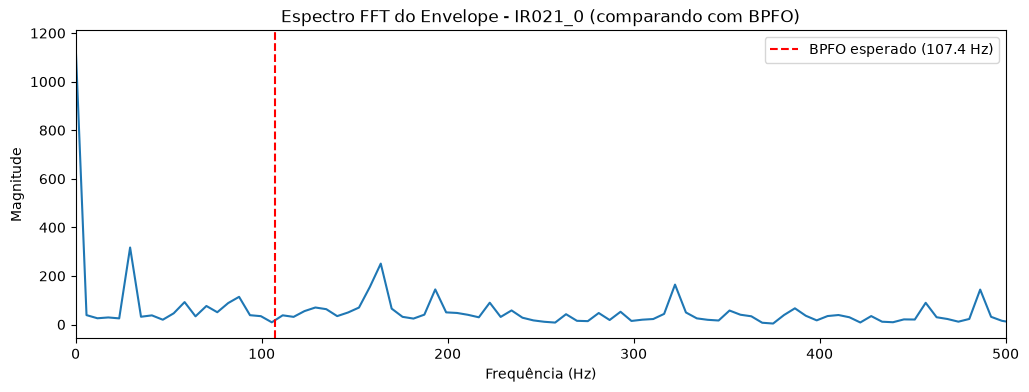

In [36]:
def plotar_espectro_envelope(caminho_arquivo, titulo, freq_esperada=None, rotulo_freq=None):
    """
    Carrega um arquivo, calcula o envelope da primeira janela, aplica FFT,
    e plota o espectro — opcionalmente marcando uma frequência teórica esperada.
    """
    sinal = carregar_sinal(caminho_arquivo)
    janela = segmentar_sinal(sinal, 2048)[0]
    envelope = calcular_envelope(janela)
    freqs, mags = calcular_fft(envelope)

    plt.figure(figsize=(12, 4))
    plt.plot(freqs, mags)

    if freq_esperada is not None:
        plt.axvline(x=freq_esperada, color="red", linestyle="--", linewidth=1.5,
                    label=f"{rotulo_freq} esperado ({freq_esperada:.1f} Hz)")
        plt.legend()

    plt.xlabel("Frequência (Hz)")
    plt.ylabel("Magnitude")
    plt.title(titulo)
    plt.xlim(0, 500)
    plt.show()

rpm_normal = carregar_rpm("../data/raw/Normal_0.mat")
bpfo_normal = calcular_frequencias_falha(rpm_normal)["bpfo"]

plotar_espectro_envelope(
    "../data/raw/Normal_0.mat",
    titulo="Espectro FFT do Envelope - Normal_0",
    freq_esperada=bpfo_normal,
    rotulo_freq="BPFO"
)

rpm_ir = carregar_rpm("../data/raw/IR021_0.mat")
frequencias_ir = calcular_frequencias_falha(rpm_ir)

plotar_espectro_envelope(
    "../data/raw/IR021_0.mat",
    titulo="Espectro FFT do Envelope - IR021_0",
    freq_esperada=frequencias_ir["bpfi"],
    rotulo_freq="BPFI"
)

plotar_espectro_envelope(
    "../data/raw/IR021_0.mat",
    titulo="Espectro FFT do Envelope - IR021_0 (comparando com BPFO)",
    freq_esperada=frequencias_ir["bpfo"],
    rotulo_freq="BPFO"
)